# 01 – EDA và phân tích 3B (Problem Definition + Data Understanding)

- **Học phần:** Ứng dụng AI trong công nghiệp
- **Dataset:** SECOM (1567 mẫu, 590 đặc trưng, nhãn Pass/Fail, có timestamp)
- **Mục tiêu của notebook:** Phát biểu bài toán, hiểu cấu trúc và chất lượng dữ liệu SECOM, rút ra quyết định tiền xử lý cho chương 4.
- **Bước lifecycle:** 1. Problem Definition và 2. Data Understanding
- **Bài lab của thầy tham chiếu:** Lab 01
- **Input (đọc từ):** `data/secom/secom.data`, `data/secom/secom_labels.data`
- **Output (lưu vào):** hình EDA vào `figures/`, bảng 3B (Broken / Bad Quality / Background) vào `artifacts/eda_3B.csv`

In [1]:
# Chuẩn bị thư viện và đường dẫn
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from secom_utils import load_secom, get_split

SEED = 42
DATA_DIR = Path("data/secom")
FIG_DIR = Path("figures")
ARTIFACT_DIR = Path("artifacts")

DATA_PATH = DATA_DIR / "secom.data"
LABEL_PATH = DATA_DIR / "secom_labels.data"

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)

## 1. Problem definition

Phát biểu theo mẫu "We want to ... for ... using ... so that ... can ..."; nêu Input/Output/Context, người dùng, quyết định cần hỗ trợ và ràng buộc.

**Phát biểu bài toán:** Chúng ta muốn **dự đoán một quan sát sản xuất bán dẫn sẽ Pass hay Fail** ở bước kiểm tra chất lượng, **cho** từng quan sát trong quy trình được ghi lại trong SECOM, **dựa trên** 590 phép đo quá trình có sẵn của quan sát đó, **để** kỹ sư quy trình / kỹ sư chất lượng **quyết định** quan sát nào cần kiểm tra thêm hoặc cần điều tra lại quá trình.

| Thành phần | Nội dung |
|---|---|
| **Input** | 590 phép đo quá trình của mỗi quan sát (số thực, có giá trị thiếu `NaN`) |
| **Output** | Nhãn Pass (0) / Fail (1), hoặc điểm rủi ro Fail để xếp hạng quan sát cần kiểm tra |
| **Context** | Có nhãn Pass/Fail và timestamp của mỗi quan sát. Dataset **thiếu**: tên và ý nghĩa của từng cột, đơn vị đo, công đoạn đo, định nghĩa cụ thể của Fail, thời điểm gán nhãn, chi phí của việc bỏ sót Fail hay báo nhầm |

- **Vấn đề thực tế:** quy trình bán dẫn có rất nhiều điểm đo; khi một lô Fail, khó biết sớm và khó biết nên nhìn vào tín hiệu nào.
- **Khó khăn:** số đặc trưng lớn, nhiều cột thiếu dữ liệu hoặc không biến thiên, Fail rất hiếm, không có ngữ cảnh vật lý cho các cột.
- **Mục tiêu:** xây dựng mô hình phân loại phát hiện được Fail (Recall của Fail) mà không báo nhầm quá nhiều (Precision của Fail).
- **Đối tượng sử dụng:** kỹ sư quy trình, kỹ sư chất lượng.
- **Quyết định cần hỗ trợ:** quan sát nào nên được kiểm tra thêm / ưu tiên điều tra quá trình.
- **Ràng buộc:**
  1. Fail hiếm, nên Accuracy không phải thước đo phù hợp.
  2. Nhiều cột thiếu dữ liệu, cần xử lý trước khi đưa vào mô hình.
  3. Không có ngữ cảnh cảm biến, nên không diễn giải được ý nghĩa vật lý của từng cột.
  4. Dự đoán chỉ **hỗ trợ** con người ra quyết định, không tự động loại bỏ sản phẩm.
  5. Đầu vào của mô hình phải có sẵn tại thời điểm dự đoán (không dùng nhãn hay thông tin sau kiểm tra).

## 2. Đọc dữ liệu và kiểm tra cấu trúc file

Đọc `secom.data` và `secom_labels.data`; kiểm tra mọi dòng đúng 590 trường, không tự thêm cột thứ 591.

In [2]:
# Đọc ma trận đặc trưng: các giá trị phân cách bằng một hoặc nhiều khoảng trắng
df_raw = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None
)

print("Kích thước dữ liệu:", df_raw.shape)

Kích thước dữ liệu: (1567, 590)


In [3]:
# Đếm số trường trên từng dòng của file gốc
field_counts = []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for line in f:
        field_counts.append(len(line.split()))

print("Số dòng:", len(field_counts))
print("Số trường nhỏ nhất:", min(field_counts))
print("Số trường lớn nhất:", max(field_counts))
print("Các số trường khác nhau:", sorted(set(field_counts)))

Số dòng: 1567
Số trường nhỏ nhất: 590
Số trường lớn nhất: 590
Các số trường khác nhau: [590]


### 590 hay 591 features?

Trang UCI ghi SECOM có **591 features**, nhưng file `secom.data` thực tế có **590 trường trên mọi dòng** (kết quả ô trên). Vì vậy đọc ra `(1567, 590)` không phải do `read_csv` làm mất cột.

Ta dùng đúng cấu trúc của file thực tế: **590 cột**, **không tự thêm một cột `NaN`** để thành 591.

In [4]:
print("Thông tin DataFrame:")
df_raw.info()

print("\n5 dòng đầu:")
display(df_raw.head())

print("\n5 dòng cuối:")
display(df_raw.tail())

print("\nThống kê mô tả:")
display(df_raw.describe().T.head(15))

Thông tin DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 590 entries, 0 to 589
dtypes: float64(590)
memory usage: 7.1 MB

5 dòng đầu:


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432



5 dòng cuối:


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
1562,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,-0.0045,...,0.0047,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720
1563,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,-0.0061,...,NaN,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720
1564,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,NaN,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231
1565,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,-0.0072,...,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941
1566,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,NaN,...,0.0045,137.7844,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844



Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
0,1561.0,3014.452896,73.621787,2743.2400,2966.260000,3011.4900,3056.650000,3356.3500
1,1560.0,2495.850231,80.407705,2158.7500,2452.247500,2499.4050,2538.822500,2846.4400
2,1553.0,2200.547318,29.513152,2060.6600,2181.044400,2201.0667,2218.055500,2315.2667
3,1553.0,1396.376627,441.691640,0.0000,1081.875800,1285.2144,1591.223500,3715.0417
4,1553.0,4.197013,56.355540,0.6815,1.017700,1.3168,1.525700,1114.5366
5,1553.0,100.000000,0.000000,100.0000,100.000000,100.0000,100.000000,100.0000
6,1553.0,101.112908,6.237214,82.1311,97.920000,101.5122,104.586700,129.2522
7,1558.0,0.121822,0.008961,0.0000,0.121100,0.1224,0.123800,0.1286
8,1565.0,1.462862,0.073897,1.1910,1.411200,1.4616,1.516900,1.6564
9,1565.0,-0.000841,0.015116,-0.0534,-0.010800,-0.0013,0.008400,0.0749


### Nhận xét

- **Phát hiện:** file có 1.567 dòng × 590 cột, mọi dòng đúng 590 trường, tất cả cột kiểu `float64`. Các cột không có tên, chỉ có chỉ số 0–589, nên không tự gán ý nghĩa vật lý cho từng cột.
- Ngay ở 5 dòng đầu đã có `NaN` (ví dụ cột 580, 581, 586–589), và trong `describe` cột 5, 13 có `std = 0` → dấu hiệu thiếu dữ liệu và cột hằng, kiểm tra kỹ ở mục 5 và 6.
- Thang đo khác nhau rõ: cột 0 quanh 3.000, cột 9 quanh 0 (std 0,015) → xem trên cả 590 cột ở mục 7.
- **Kết luận:** dữ liệu đọc đúng cấu trúc, nhưng chưa "sạch".

## 3. Nhãn và timestamp

Đổi nhãn -1/1 thành 0/1, ghép ngày giờ thành timestamp, kiểm tra thứ tự dòng theo thời gian.

In [5]:
# Đọc file nhãn bằng engine mặc định (không đặt engine="python")
labels_raw = pd.read_csv(
    LABEL_PATH,
    sep=r"\s+",
    header=None
)

print("Kích thước nhãn:", labels_raw.shape)
display(labels_raw.head())

print("Kiểu dữ liệu:")
print(labels_raw.dtypes)

Kích thước nhãn: (1567, 2)


,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


Kiểu dữ liệu:
0    int64
1      str
dtype: object


In [6]:
# Lấy chuỗi ngày giờ; nếu ngày và giờ bị tách thành 2 cột thì ghép lại
if labels_raw.shape[1] == 3:
    time_text = labels_raw[1].astype(str) + " " + labels_raw[2].astype(str)
else:
    time_text = labels_raw[1].astype(str)

# Parse theo định dạng ngày/tháng/năm giờ:phút:giây, giá trị lỗi sẽ thành NaT
timestamps = pd.to_datetime(time_text, format="%d/%m/%Y %H:%M:%S", errors="coerce")
time_span = timestamps.max() - timestamps.min()

print("Số timestamp lỗi:", timestamps.isna().sum())
print("Timestamp tăng dần theo thứ tự dòng:", timestamps.is_monotonic_increasing)
print("Ngày bắt đầu:", timestamps.min())
print("Ngày kết thúc:", timestamps.max())
print("Khoảng thời gian:", time_span)
print("Số ngày có dữ liệu:", timestamps.dt.date.nunique())

Số timestamp lỗi: 0
Timestamp tăng dần theo thứ tự dòng: True
Ngày bắt đầu: 2008-07-19 11:55:00
Ngày kết thúc: 2008-10-17 06:07:00
Khoảng thời gian: 89 days 18:12:00
Số ngày có dữ liệu: 86


In [7]:
# Ánh xạ nhãn: -1 -> 0 (Pass), 1 -> 1 (Fail)
y_labels = labels_raw[0].map({-1: 0, 1: 1})

print("Giá trị nhãn gốc:", sorted(labels_raw[0].unique()))
print("Giá trị nhãn sau khi đổi:", sorted(y_labels.unique()))

Giá trị nhãn gốc: [np.int64(-1), np.int64(1)]
Giá trị nhãn sau khi đổi: [np.int64(0), np.int64(1)]


### Phân bố nhãn

Phân bố nhãn tính trên **toàn bộ dữ liệu**, chỉ để **mô tả**; không dùng để chọn đặc trưng hay chọn ngưỡng.

In [8]:
class_count = y_labels.value_counts().sort_index()
class_percent = y_labels.value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "count": class_count,
    "percent": class_percent
})
class_summary.index = ["Pass (0)", "Fail (1)"]

display(class_summary.round(2))

,count,percent
Pass (0),1463,93.36
Fail (1),104,6.64


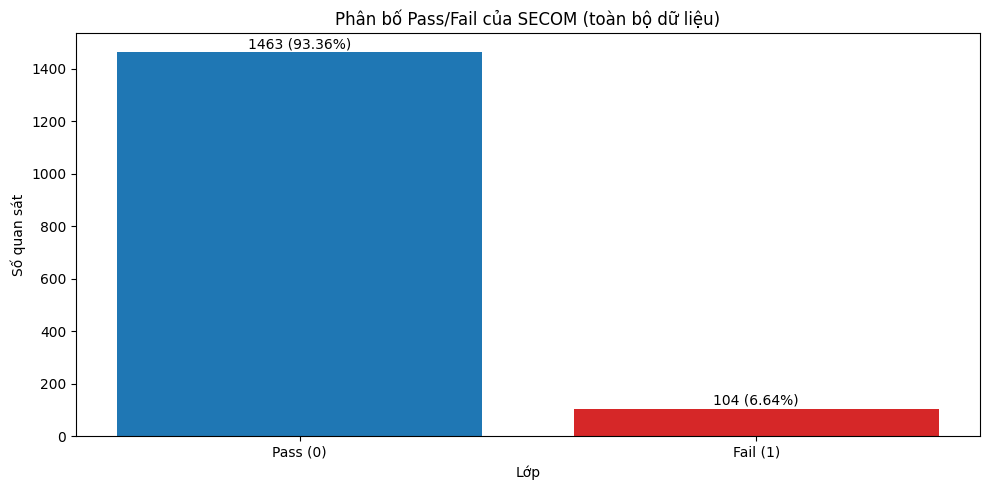

In [9]:
plt.figure(figsize=(10, 5))
plt.bar(class_summary.index, class_summary["count"], color=["tab:blue", "tab:red"])

# Ghi số lượng và tỉ lệ lên từng cột
for position, label in enumerate(class_summary.index):
    count = class_summary.loc[label, "count"]
    percent = class_summary.loc[label, "percent"]
    plt.text(position, count + 15, f"{count} ({percent:.2f}%)", ha="center")

plt.title("Phân bố Pass/Fail của SECOM (toàn bộ dữ liệu)")
plt.xlabel("Lớp")
plt.ylabel("Số quan sát")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_class_distribution.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** đọc bằng engine mặc định ra đúng 2 cột (nhãn và chuỗi ngày giờ). Cả 1.567 timestamp parse được, không lỗi, tăng dần theo thứ tự dòng, từ 19/07/2008 đến 17/10/2008 (khoảng 90 ngày, 86 ngày có dữ liệu).
- Pass = 1.463 (93,36%), Fail = 104 (6,64%) → mất cân bằng nghiêm trọng, khoảng 14 Pass cho 1 Fail.
- **Ảnh hưởng:** một mô hình luôn dự đoán Pass vẫn có Accuracy 93,36%, nhưng Recall của Fail = 0, tức không phát hiện được lô lỗi nào.
- **Kết luận:** không dùng Accuracy làm thước đo chính; theo dõi Recall, Precision, F1 của Fail và PR-AUC; xử lý mất cân bằng ở chương 4.

### Hàm dùng chung `load_secom`

Các notebook 02–06 đọc dữ liệu bằng `load_secom`. Ô dưới kiểm tra hàm này cho kết quả giống hệt phần vừa đọc thủ công.

In [10]:
# Đọc lại bằng hàm dùng chung
X, y, timestamps_loaded = load_secom(DATA_DIR)

# Kiểm tra kết quả khớp với phần đọc thủ công
assert X.shape == (1567, 590)
assert X.equals(df_raw.astype(float))
assert (y.values == y_labels.values).all()
assert sorted(y.unique()) == [0, 1]
assert timestamps_loaded.equals(timestamps)

print("load_secom khớp với dữ liệu đọc thủ công.")
print("X:", X.shape, "| y:", y.shape, "| timestamps:", timestamps_loaded.shape)

load_secom khớp với dữ liệu đọc thủ công.
X: (1567, 590) | y: (1567,) | timestamps: (1567,)


## 4. Chia train/test stratified 80/20 (seed 42)

Dùng hàm trong `secom_utils`. Từ mục 7 trở đi, mọi phân tích có dùng nhãn chỉ chạy trên tập train.

In [11]:
# get_split trả về chỉ số vị trí của train và test
train_idx, test_idx = get_split(y, test_size=0.20, seed=SEED)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1253, 590)
X_test : (314, 590)
y_train: (1253,)
y_test : (314,)


In [12]:
# So sánh phân bố Pass/Fail giữa toàn bộ dữ liệu, train và test
split_summary = pd.DataFrame({
    "Full - count": y.value_counts(),
    "Full - %": y.value_counts(normalize=True) * 100,
    "Train - count": y_train.value_counts(),
    "Train - %": y_train.value_counts(normalize=True) * 100,
    "Test - count": y_test.value_counts(),
    "Test - %": y_test.value_counts(normalize=True) * 100
}).sort_index()
split_summary.index = ["Pass (0)", "Fail (1)"]

display(split_summary.round(2))

,Full - count,Full - %,Train - count,Train - %,Test - count,Test - %
Pass (0),1463,93.36,1170,93.38,293,93.31
Fail (1),104,6.64,83,6.62,21,6.69


### Nhận xét

- **Phát hiện:** train 1.253 mẫu (1.170 Pass / 83 Fail), test 314 mẫu (293 Pass / 21 Fail). Tỉ lệ Fail ở train 6,62%, test 6,69%, sát mức 6,64% của toàn bộ → `stratify` giữ được tỉ lệ Fail.
- Chia **trước** khi học bất kỳ tham số nào (ngưỡng missing, trung vị, scale, chọn đặc trưng) để thông tin của test không rò vào quá trình xây dựng mô hình.
- **Ảnh hưởng:** test chỉ có 21 Fail, mỗi Fail đúng/sai làm Recall thay đổi khoảng 4,8 điểm %, nên kết quả trên test sẽ dao động nhiều.
- **Kết luận:** từ đây phân tích có dùng nhãn (PCA tô màu ở mục 9) chỉ chạy trên train; mục 8 dùng nhãn toàn bộ chỉ để mô tả.

## 5. Giá trị thiếu

Thống kê theo cột và theo dòng, histogram tỉ lệ missing, bảng ngưỡng cho biết loại bao nhiêu cột ở mỗi ngưỡng.

Các thống kê ở mục 5–7 không dùng nhãn nên chạy trên **toàn bộ `X`** (giống Lab 01, Lab 02).

### 5.1. Tổng quan và top 20 cột thiếu nhiều nhất

In [13]:
missing_count = X.isna().sum()
missing_rate = X.isna().mean()
total_missing = int(missing_count.sum())
total_cells = X.shape[0] * X.shape[1]
missing_percent = total_missing / total_cells * 100

print("Tổng số giá trị thiếu:", total_missing)
print("Tỉ lệ thiếu trên toàn ma trận (%):", round(missing_percent, 2))
print("Số biến có ít nhất một giá trị thiếu:", int((missing_count > 0).sum()))
print("Số biến không có giá trị thiếu:", int((missing_count == 0).sum()))

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_rate_percent": missing_rate * 100
}).sort_values("missing_rate_percent", ascending=False)

display(missing_summary.head(20))

Tổng số giá trị thiếu: 41951
Tỉ lệ thiếu trên toàn ma trận (%): 4.54
Số biến có ít nhất một giá trị thiếu: 538
Số biến không có giá trị thiếu: 52


,missing_count,missing_rate_percent
292,1429,91.193363
293,1429,91.193363
158,1429,91.193363
157,1429,91.193363
492,1341,85.577537
85,1341,85.577537
358,1341,85.577537
220,1341,85.577537
244,1018,64.964901
517,1018,64.964901


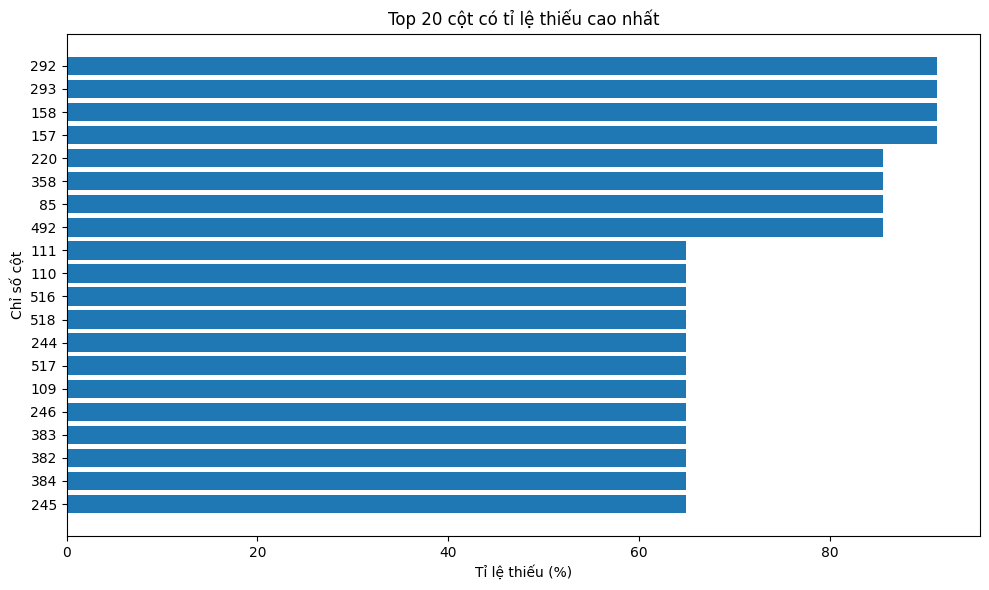

In [14]:
top_missing = missing_summary.head(20).sort_values("missing_rate_percent")

plt.figure(figsize=(10, 6))
plt.barh(top_missing.index.astype(str), top_missing["missing_rate_percent"])
plt.xlabel("Tỉ lệ thiếu (%)")
plt.ylabel("Chỉ số cột")
plt.title("Top 20 cột có tỉ lệ thiếu cao nhất")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_missing_top20.png", dpi=150)
plt.show()

### 5.2. Phân bố tỉ lệ thiếu của 590 cột

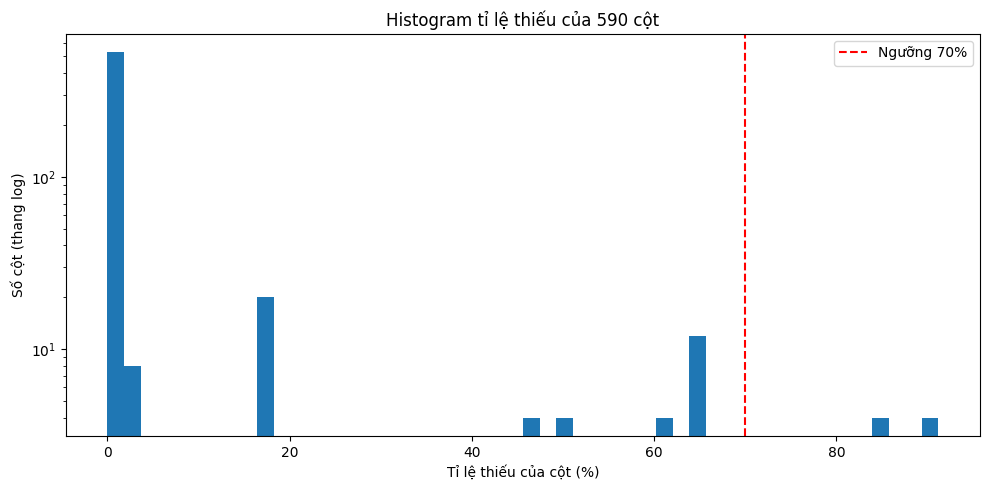

In [15]:
MISSING_THRESHOLD = 0.70

plt.figure(figsize=(10, 5))
plt.hist(missing_rate * 100, bins=50)
plt.axvline(MISSING_THRESHOLD * 100, color="red", linestyle="--", label="Ngưỡng 70%")
plt.yscale("log")
plt.xlabel("Tỉ lệ thiếu của cột (%)")
plt.ylabel("Số cột (thang log)")
plt.title("Histogram tỉ lệ thiếu của 590 cột")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_missing_hist.png", dpi=150)
plt.show()

### 5.3. Số cột bị loại theo từng ngưỡng

Lab 02 dùng ngưỡng 70%, nhưng đó là **quy ước của bài thực hành**, không phải chuẩn công nghiệp. Bảng dưới xem kết quả thay đổi thế nào nếu đổi ngưỡng.

In [16]:
threshold_rows = []
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    n_removed = int((missing_rate > threshold).sum())
    threshold_rows.append({
        "Ngưỡng": f"> {int(threshold * 100)}%",
        "Số cột bị loại": n_removed,
        "Số cột còn lại": X.shape[1] - n_removed
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,Ngưỡng,Số cột bị loại,Số cột còn lại
0,> 50%,28,562
1,> 60%,24,566
2,> 70%,8,582
3,> 80%,8,582
4,> 90%,4,586


In [17]:
# Các mức tỉ lệ thiếu thực tế của những cột thiếu hơn 50%
high_missing_levels = missing_summary[missing_summary["missing_rate_percent"] > 50]
high_missing_levels = high_missing_levels.groupby(["missing_count", "missing_rate_percent"]).size()

display(high_missing_levels.rename("số cột").sort_index(ascending=False).to_frame())

,,số cột
missing_count,missing_rate_percent,
1429,91.193363,4
1341,85.577537,4
1018,64.964901,12
949,60.561583,4
794,50.670070,4


### Nhận xét

- **Phát hiện:** 41.951 ô thiếu (4,54% ma trận); 538/590 cột có ít nhất một ô thiếu, chỉ 52 cột đầy đủ. Histogram cho thấy phần lớn cột thiếu rất ít, chỉ vài nhóm cột thiếu nhiều.
- Tỉ lệ thiếu cao tập trung ở vài mức: 91,19% (4 cột), 85,58% (4 cột), 64,96% (12 cột), 60,56% (4 cột), 50,67% (4 cột). Từ 64,96% đến 85,58% không có cột nào, nên mọi ngưỡng trong khoảng này (70% hay 80%) đều loại đúng 8 cột (590 → 582).
- **Ảnh hưởng:** với cột thiếu trên 85%, phần lớn giá trị sau impute là giá trị điền chứ không phải dữ liệu thật. Ngược lại, hạ ngưỡng xuống 60% hay 50% sẽ loại thêm 16–20 cột vẫn còn khoảng 35–49% dữ liệu thật.
- **Kết luận:** dùng ngưỡng 70% như Lab 02; kết quả không đổi nếu ngưỡng nằm trong khoảng 65–85%. Đây vẫn là quy ước, không phải chuẩn công nghiệp, và ở notebook 02 ngưỡng sẽ được áp dụng khi học trên train.

### 5.4. Nhóm cột có cùng số ô thiếu

In [18]:
# Với các cột có missing: đếm xem bao nhiêu cột có cùng một số ô thiếu
columns_with_missing = missing_count[missing_count > 0]
same_missing_groups = columns_with_missing.value_counts()

print("Số cột có missing:", len(columns_with_missing))
print("Số mức missing_count khác nhau:", len(same_missing_groups))

group_table = pd.DataFrame({
    "Số ô thiếu mỗi cột": same_missing_groups.index,
    "Số cột": same_missing_groups.values
})
display(group_table.head(10))

Số cột có missing: 538
Số mức missing_count khác nhau: 22


,Số ô thiếu mỗi cột,Số cột
0,6,100
1,1,92
2,2,84
3,9,48
4,24,43
5,3,24
6,4,24
7,7,20
8,14,20
9,1018,12


### 5.5. Missing theo dòng (số ô thiếu mỗi mẫu)

In [19]:
missing_per_row = X.isna().sum(axis=1)

print("Thống kê số ô thiếu mỗi mẫu:")
display(missing_per_row.describe().to_frame("missing_per_row").T)

Thống kê số ô thiếu mỗi mẫu:


,count,mean,std,min,25%,50%,75%,max
missing_per_row,1567.0,26.771538,13.377518,4.0,20.0,24.0,32.0,152.0


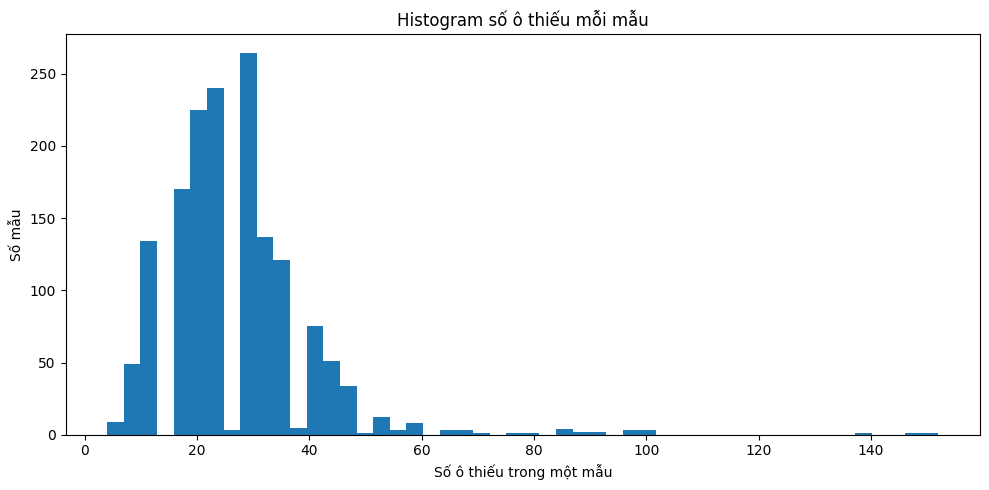

In [20]:
plt.figure(figsize=(10, 5))
plt.hist(missing_per_row, bins=50)
plt.xlabel("Số ô thiếu trong một mẫu")
plt.ylabel("Số mẫu")
plt.title("Histogram số ô thiếu mỗi mẫu")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_missing_per_row.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** 538 cột có missing nhưng chỉ có 22 mức số ô thiếu khác nhau: 100 cột cùng thiếu 6 ô, 92 cột cùng thiếu 1 ô, 12 cột cùng thiếu 1.018 ô...
- Nhiều cột thiếu cùng một số ô gợi ý chúng có thể bị thiếu cùng nhau (trên cùng các mẫu), nhưng dữ liệu không đủ bằng chứng để nói nguyên nhân.
- Theo dòng: mỗi mẫu thiếu từ 4 đến 152 ô (trung vị 24, trung bình 26,8) → **không có mẫu nào đầy đủ**, nên không thể xoá các dòng có missing.
- **Kết luận:** giữ mọi dòng và impute trung vị (fit trên train); missing indicator chỉ thử như ablation.

## 6. Dòng trùng và cột hằng

Đếm dòng trùng và cột có phương sai bằng 0.

In [21]:
duplicate_rows = X.duplicated().sum()
print("Số dòng trùng lặp hoàn toàn:", duplicate_rows)

Số dòng trùng lặp hoàn toàn: 0


In [22]:
# Cột hằng: phương sai bằng 0 (bỏ qua NaN)
variance = X.var(axis=0, skipna=True)
constant_features = variance[variance == 0].index

print("Số biến có phương sai bằng 0:", len(constant_features))
print("10 chỉ số cột hằng đầu tiên:", list(constant_features[:10]))

Số biến có phương sai bằng 0: 116
10 chỉ số cột hằng đầu tiên: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178]


In [23]:
# Cột gần hằng: giá trị phổ biến nhất chiếm > 99% số quan sát không thiếu, nhưng chưa phải cột hằng
NEAR_CONSTANT_RATIO = 0.99
non_constant_columns = X.columns.drop(constant_features)

near_constant_features = []
for col in non_constant_columns:
    # value_counts mặc định bỏ qua NaN
    top_value_ratio = X[col].value_counts(normalize=True).iloc[0]
    if top_value_ratio > NEAR_CONSTANT_RATIO:
        near_constant_features.append(col)

print("Số cột gần hằng:", len(near_constant_features))
print("Chỉ số các cột gần hằng:", near_constant_features)

Số cột gần hằng: 6
Chỉ số các cột gần hằng: [74, 206, 209, 342, 347, 478]


In [24]:
# Số cột sau từng bước lọc (đếm mô tả trên toàn bộ X, giống Lab 02)
high_missing_features = missing_rate[missing_rate > MISSING_THRESHOLD].index
X_after_missing_eda = X.drop(columns=high_missing_features)
X_after_eda = X_after_missing_eda.drop(columns=constant_features, errors="ignore")

feature_summary = pd.DataFrame({
    "Giai đoạn": ["Dữ liệu gốc", "Sau khi loại cột thiếu > 70%", "Sau khi loại cột hằng"],
    "Số cột": [X.shape[1], X_after_missing_eda.shape[1], X_after_eda.shape[1]]
})
display(feature_summary)
print("Đây là số đếm mô tả; pipeline thật sẽ học các bước lọc trên train ở notebook 02.")

,Giai đoạn,Số cột
0,Dữ liệu gốc,590
1,Sau khi loại cột thiếu > 70%,582
2,Sau khi loại cột hằng,466


Đây là số đếm mô tả; pipeline thật sẽ học các bước lọc trên train ở notebook 02.


### Nhận xét

- **Phát hiện:** không có dòng trùng hoàn toàn (0). Có 116 cột phương sai bằng 0 và thêm 6 cột gần hằng (74, 206, 209, 342, 347, 478), giá trị phổ biến nhất chiếm hơn 99% số quan sát không thiếu.
- **Ảnh hưởng:** cột hằng không có thông tin phân biệt; cột gần hằng có rất ít thông tin, vài giá trị khác thường của chúng có thể trùng với vài mẫu Fail một cách ngẫu nhiên vì số Fail ít.
- Số cột: 590 → 582 (loại thiếu > 70%) → 466 (loại cột hằng), khớp Lab 02. Đây chỉ là số đếm mô tả trên toàn bộ `X`; pipeline thật học trên train ở notebook 02.
- **Kết luận:** loại cột hằng; cột gần hằng chưa loại riêng mà để bước chọn đặc trưng quyết định. Không trùng lặp không có nghĩa là dữ liệu đã sạch.

## 7. Outlier và thang đo trên cả 590 cột

Tóm tắt theo cột: tỉ lệ ngoài IQR, skewness, độ lệch chuẩn thang log; chỉ vẽ vài cột đại diện.

### 7.1. Chọn cột để tính outlier

Chỉ xét các cột **không hằng** và có **IQR > 0**. Nếu IQR = 0 thì biên Q1 − 1.5·IQR và Q3 + 1.5·IQR trùng với trung vị, nên gần như mọi giá trị khác trung vị đều bị đánh dấu là outlier, con số không còn ý nghĩa.

In [25]:
X_nonconstant = X.drop(columns=constant_features)

# Tứ phân vị và IQR theo cột (bỏ qua NaN)
q1 = X_nonconstant.quantile(0.25)
q3 = X_nonconstant.quantile(0.75)
iqr = q3 - q1
iqr_columns = iqr[iqr > 0].index

print("Số cột không hằng:", X_nonconstant.shape[1])
print("Số cột không hằng nhưng IQR = 0:", int((iqr == 0).sum()))
print("Số cột dùng để tính outlier:", len(iqr_columns))

Số cột không hằng: 474
Số cột không hằng nhưng IQR = 0: 10
Số cột dùng để tính outlier: 464


### 7.2. Tỉ lệ outlier theo luật IQR

In [26]:
X_iqr = X_nonconstant[iqr_columns]
lower_bound = q1[iqr_columns] - 1.5 * iqr[iqr_columns]
upper_bound = q3[iqr_columns] + 1.5 * iqr[iqr_columns]

# Đánh dấu giá trị ngoài biên (so sánh với NaN luôn ra False nên NaN không bị tính)
is_outlier = X_iqr.lt(lower_bound, axis=1) | X_iqr.gt(upper_bound, axis=1)

# Tỉ lệ outlier = số giá trị ngoài biên / số giá trị không thiếu của cột
outlier_ratio = is_outlier.sum() / X_iqr.notna().sum()

print("Thống kê tỉ lệ outlier (%) theo cột:")
display((outlier_ratio * 100).describe().to_frame("outlier_ratio_%").T.round(2))
print("Số cột có hơn 5% outlier:", int((outlier_ratio > 0.05).sum()), "/", len(iqr_columns))

Thống kê tỉ lệ outlier (%) theo cột:


,count,mean,std,min,25%,50%,75%,max
outlier_ratio_%,464.0,3.61,3.53,0.0,1.03,2.69,4.92,22.62


Số cột có hơn 5% outlier: 110 / 464


In [27]:
outlier_table = pd.DataFrame({
    "Q1": q1[iqr_columns],
    "Q3": q3[iqr_columns],
    "IQR": iqr[iqr_columns],
    "lower_bound": lower_bound,
    "upper_bound": upper_bound,
    "outlier_ratio_%": outlier_ratio * 100
}).sort_values("outlier_ratio_%", ascending=False)

print("Top 10 cột có tỉ lệ outlier cao nhất:")
display(outlier_table.head(10).round(4))

Top 10 cột có tỉ lệ outlier cao nhất:


,Q1,Q3,IQR,lower_bound,upper_bound,outlier_ratio_%
31,3.3627,3.5313,0.1686,3.1098,3.7842,22.6198
40,74.8000,80.2000,5.4000,66.7000,88.3000,21.3869
562,259.9725,265.7070,5.7345,251.3708,274.3087,16.6151
129,-0.8988,0.0473,0.9461,-2.3180,1.4664,15.2760
544,0.0024,0.0026,0.0002,0.0021,0.0029,15.2716
312,0.0915,0.1602,0.0687,-0.0115,0.2632,14.9425
195,0.2180,0.2960,0.0780,0.1010,0.4130,14.9072
448,0.1877,0.3511,0.1634,-0.0574,0.5962,14.6871
177,0.2220,0.4230,0.2010,-0.0795,0.7245,14.6871
467,4.6975,6.3869,1.6894,2.1634,8.9210,13.9475


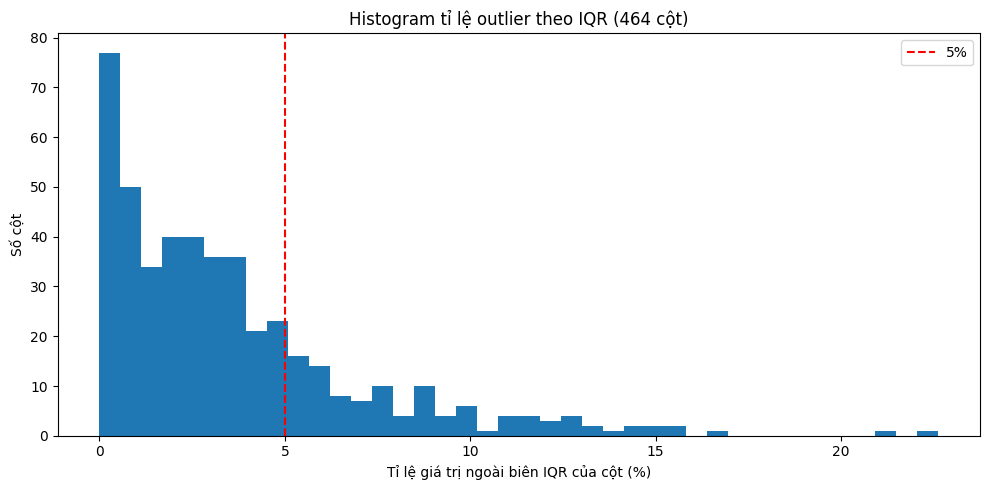

In [28]:
plt.figure(figsize=(10, 5))
plt.hist(outlier_ratio * 100, bins=40)
plt.axvline(5, color="red", linestyle="--", label="5%")
plt.xlabel("Tỉ lệ giá trị ngoài biên IQR của cột (%)")
plt.ylabel("Số cột")
plt.title(f"Histogram tỉ lệ outlier theo IQR ({len(iqr_columns)} cột)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_outlier_summary.png", dpi=150)
plt.show()

### 7.3. Độ lệch (skewness) theo cột

Số cột không hằng: 474
Số cột có |skew| > 2: 269
Trung vị của |skew|: 2.54


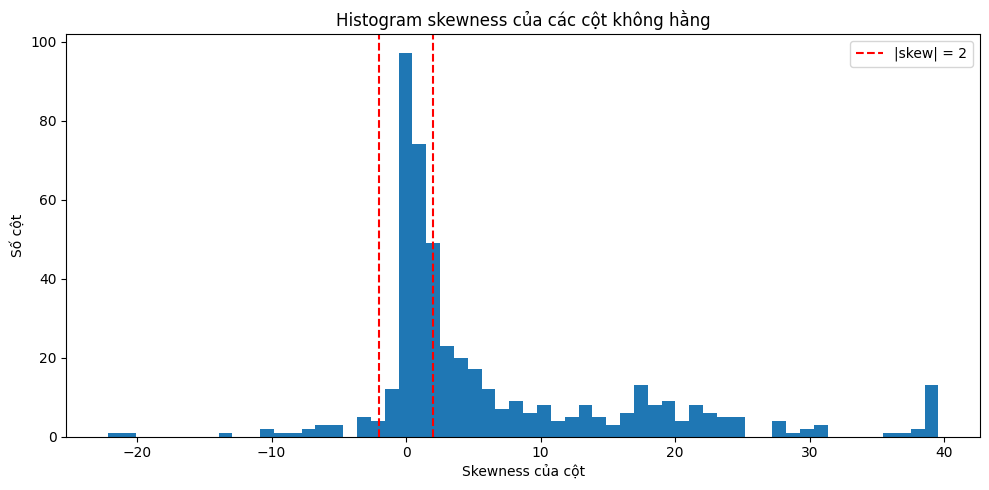

In [29]:
skewness = X_nonconstant.skew()

print("Số cột không hằng:", len(skewness))
print("Số cột có |skew| > 2:", int((skewness.abs() > 2).sum()))
print("Trung vị của |skew|:", round(skewness.abs().median(), 2))

plt.figure(figsize=(10, 5))
plt.hist(skewness, bins=60)
plt.axvline(2, color="red", linestyle="--", label="|skew| = 2")
plt.axvline(-2, color="red", linestyle="--")
plt.xlabel("Skewness của cột")
plt.ylabel("Số cột")
plt.title("Histogram skewness của các cột không hằng")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_skewness.png", dpi=150)
plt.show()

### 7.4. Thang đo: độ lệch chuẩn của từng cột

Độ lệch chuẩn nhỏ nhất: 0.00010440797375672332
Độ lệch chuẩn trung vị: 1.176527132219038
Độ lệch chuẩn lớn nhất: 6553.569317232143
Tỉ số max/min: 62768858.36806241


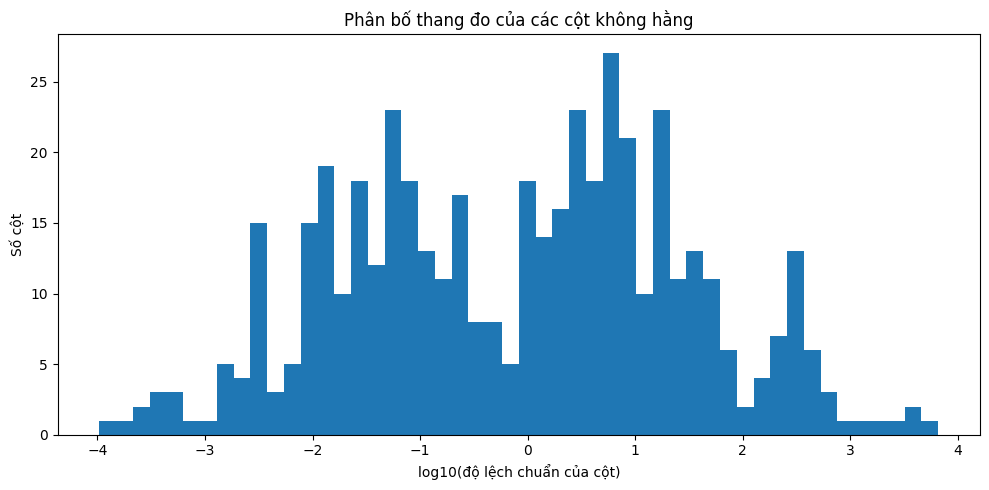

In [30]:
feature_std = X_nonconstant.std()
log_std = np.log10(feature_std)

print("Độ lệch chuẩn nhỏ nhất:", feature_std.min())
print("Độ lệch chuẩn trung vị:", feature_std.median())
print("Độ lệch chuẩn lớn nhất:", feature_std.max())
print("Tỉ số max/min:", feature_std.max() / feature_std.min())

plt.figure(figsize=(10, 5))
plt.hist(log_std, bins=50)
plt.xlabel("log10(độ lệch chuẩn của cột)")
plt.ylabel("Số cột")
plt.title("Phân bố thang đo của các cột không hằng")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_scale_std.png", dpi=150)
plt.show()

### 7.5. Bốn cột đại diện

Chọn 2 cột có tỉ lệ outlier cao nhất và 2 cột lệch nhất (bỏ cột trùng).

In [31]:
top_outlier_columns = list(outlier_ratio.sort_values(ascending=False).index[:2])
top_skew_columns = list(skewness.abs().sort_values(ascending=False).index)

example_columns = list(top_outlier_columns)
for col in top_skew_columns:
    if len(example_columns) == 4:
        break
    if col not in example_columns:
        example_columns.append(col)

print("Cột nhiều outlier nhất:", top_outlier_columns)
print("4 cột đại diện:", example_columns)

Cột nhiều outlier nhất: [31, 40]
4 cột đại diện: [31, 40, 390, 252]


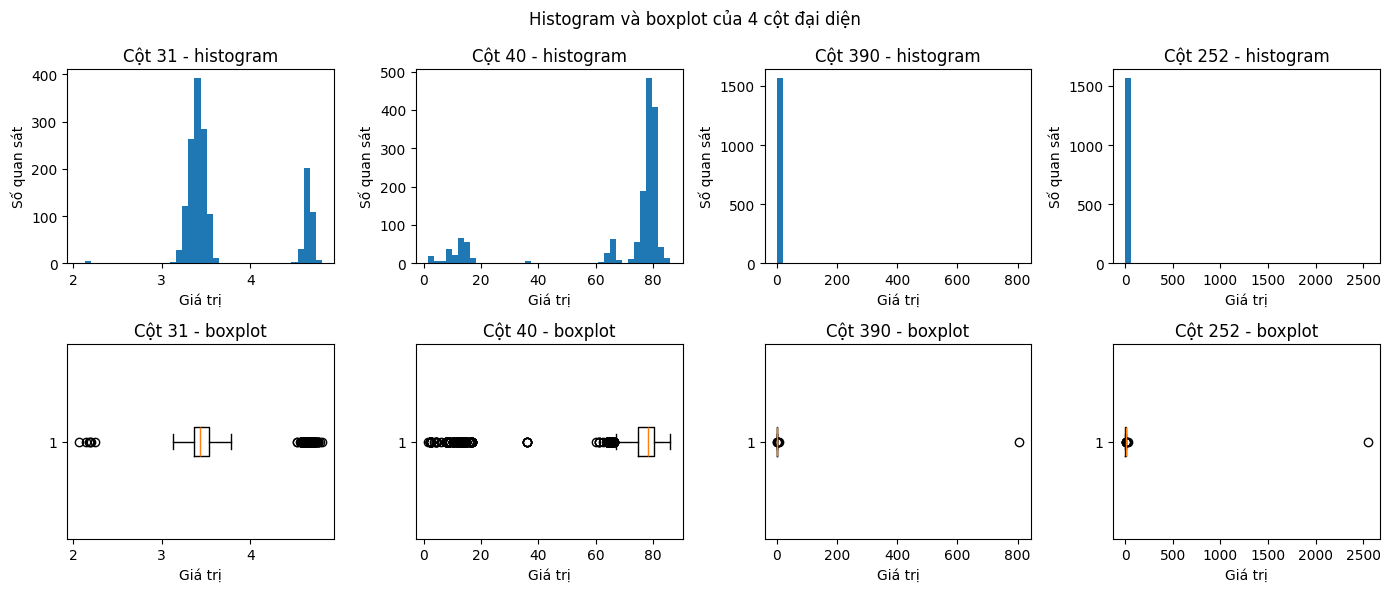

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for position, col in enumerate(example_columns):
    values = X[col].dropna()
    axes[0, position].hist(values, bins=40)
    axes[0, position].set_title(f"Cột {col} - histogram")
    axes[0, position].set_xlabel("Giá trị")
    axes[0, position].set_ylabel("Số quan sát")
    axes[1, position].boxplot(values, orientation="horizontal")
    axes[1, position].set_title(f"Cột {col} - boxplot")
    axes[1, position].set_xlabel("Giá trị")

fig.suptitle("Histogram và boxplot của 4 cột đại diện")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_outlier_examples.png", dpi=150)
plt.show()

### Nhận xét

- **Outlier:** xét 464 cột (474 cột không hằng, bỏ 10 cột IQR = 0). Tỉ lệ giá trị ngoài biên IQR có trung vị 2,69%, lớn nhất 22,62% (cột 31); 110/464 cột có hơn 5% outlier.
- Hình 4 cột đại diện: cột 31 và 40 có **hai cụm giá trị**, phần bị luật IQR đánh dấu thực chất là cả một cụm thứ hai; cột 390 và 252 gần như mọi giá trị nằm sát nhau, chỉ một giá trị rất lớn tách hẳn ra (nhìn trên boxplot) nên skew rất cao.
- **Độ lệch:** 269/474 cột có |skew| > 2, trung vị |skew| = 2,54 → đa số cột lệch mạnh. **Thang đo:** std từ khoảng 1,0e-4 đến 6.553,6, chênh khoảng 6,3 × 10⁷ lần (gần 8 bậc).
- **Ảnh hưởng và kết luận:** luật IQR chỉ là công cụ sàng lọc; giá trị cực trị trong dữ liệu công nghiệp có thể phản ánh trạng thái bất thường chứ chưa chắc là lỗi đo (như Lab 01 đã nhắc) → **không xoá outlier**, ở notebook 03 thử `RobustScaler` hoặc clipping như ablation. Thang đo chênh nhiều bậc → cần chuẩn hoá (`StandardScaler`, fit trên train) cho mô hình nhạy thang đo như Logistic Regression.

## 8. Góc nhìn theo thời gian

Tỉ lệ Fail và missing theo tuần/tháng. Chỉ để phân tích, không dùng làm feature.

- Timestamp **không** được dùng làm feature ở bất kỳ notebook nào.
- Tỉ lệ Fail theo thời gian tính trên toàn bộ dữ liệu, chỉ để **mô tả**; không dùng để chọn đặc trưng hay chọn ngưỡng.

In [33]:
# Ghép timestamp, nhãn và số ô thiếu mỗi mẫu vào một bảng
time_df = pd.DataFrame({
    "timestamp": timestamps,
    "label": y,
    "missing_per_row": missing_per_row
})

# Gom theo tuần (mỗi tuần kết thúc vào Chủ nhật)
weekly = time_df.set_index("timestamp").resample("W")
weekly_summary = pd.DataFrame({
    "n_samples": weekly["label"].count(),
    "n_fail": weekly["label"].sum(),
    "fail_rate_%": weekly["label"].mean() * 100,
    "missing_mean": weekly["missing_per_row"].mean()
})
weekly_summary.index.name = "tuần (kết thúc CN)"

display(weekly_summary.round(2))
print("Số tuần:", len(weekly_summary))
print("Số mẫu ít nhất / nhiều nhất trong một tuần:", weekly_summary["n_samples"].min(), "/", weekly_summary["n_samples"].max())

,n_samples,n_fail,fail_rate_%,missing_mean
tuần (kết thúc CN),,,,
2008-07-20,13,3,23.08,28.31
2008-07-27,21,2,9.52,28.90
2008-08-03,48,10,20.83,25.15
2008-08-10,108,14,12.96,30.87
2008-08-17,51,7,13.73,28.69
2008-08-24,208,22,10.58,30.58
2008-08-31,169,7,4.14,34.50
2008-09-07,133,2,1.50,33.98
2008-09-14,95,4,4.21,28.45


Số tuần: 14
Số mẫu ít nhất / nhiều nhất trong một tuần: 13 / 208


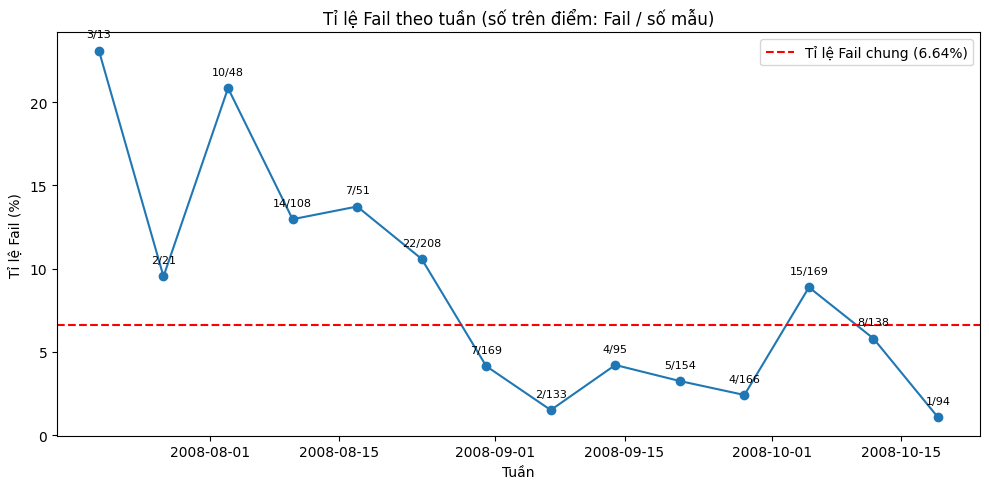

In [34]:
overall_fail_rate = y.mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(weekly_summary.index, weekly_summary["fail_rate_%"], marker="o")
plt.axhline(overall_fail_rate, color="red", linestyle="--", label=f"Tỉ lệ Fail chung ({overall_fail_rate:.2f}%)")

# Ghi số Fail / số mẫu của mỗi tuần để thấy cỡ mẫu nhỏ
for week, row in weekly_summary.iterrows():
    plt.text(week, row["fail_rate_%"] + 0.8, f"{int(row['n_fail'])}/{int(row['n_samples'])}", ha="center", fontsize=8)

plt.xlabel("Tuần")
plt.ylabel("Tỉ lệ Fail (%)")
plt.title("Tỉ lệ Fail theo tuần (số trên điểm: Fail / số mẫu)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_time_fail_rate.png", dpi=150)
plt.show()

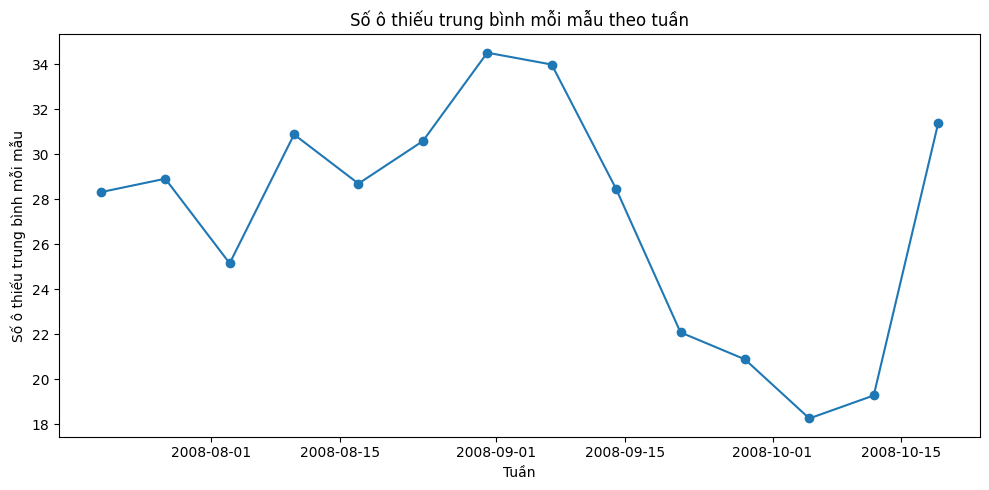

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(weekly_summary.index, weekly_summary["missing_mean"], marker="o")
plt.xlabel("Tuần")
plt.ylabel("Số ô thiếu trung bình mỗi mẫu")
plt.title("Số ô thiếu trung bình mỗi mẫu theo tuần")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_time_missing.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** 14 tuần, mỗi tuần 13–208 mẫu nên gom theo tuần là đủ. Tỉ lệ Fail theo tuần dao động từ 1,06% đến 23,08%: các tuần đến 24/08 đều từ 9,5% trở lên, từ 31/08 phần lớn tuần dưới 5% (trừ hai tuần kết thúc 05/10 và 12/10 với 8,88% và 5,80%).
- Missing trung bình mỗi mẫu cũng thay đổi: khoảng 34 ô ở cuối tháng 8 – đầu tháng 9, giảm còn khoảng 18–22 ô ở cuối tháng 9 – đầu tháng 10, rồi tăng lại 31,36 ở tuần cuối.
- **Không kết luận quá mức:** nhiều tuần chỉ có 1–7 Fail (tuần đầu chỉ 13 mẫu), vài Fail đã làm tỉ lệ thay đổi mạnh. Tuy vậy có dấu hiệu dữ liệu và tỉ lệ Fail thay đổi theo thời gian.
- **Ảnh hưởng:** random split trộn các thời điểm, train và test cùng chứa mọi giai đoạn, nên kết quả test có thể lạc quan hơn khi dự đoán dữ liệu tương lai → đưa vào chương 7 như một hạn chế. Missingness thay đổi theo thời gian nên missing indicator chỉ thử như ablation.

## 9. (Tuỳ chọn) Tương quan cao và PCA 2 chiều

Tìm các cặp cột tương quan cao; PCA 2 chiều tô màu theo Pass/Fail.

Đặt `RUN_OPTIONAL = False` để bỏ qua cả mục này.

In [36]:
RUN_OPTIONAL = True

### 9.1. Cặp cột tương quan cao

Tính trên các cột không hằng của toàn bộ `X`, **không dùng nhãn**.

In [37]:
if RUN_OPTIONAL:
    # Tương quan Pearson theo cặp, lấy trị tuyệt đối
    corr_abs = X_nonconstant.corr().abs()

    # Chỉ lấy tam giác trên (bỏ đường chéo) để mỗi cặp được đếm một lần
    upper_mask = np.triu(np.ones(corr_abs.shape, dtype=bool), k=1)
    corr_pairs = corr_abs.where(upper_mask).stack().dropna()
    corr_pairs.index.names = ["cột A", "cột B"]

    n_pairs_095 = int((corr_pairs > 0.95).sum())
    n_pairs_099 = int((corr_pairs > 0.99).sum())
    print("Tổng số cặp cột:", len(corr_pairs))
    print("Số cặp có |r| > 0.95:", n_pairs_095)
    print("Số cặp có |r| > 0.99:", n_pairs_099)
    display(corr_pairs.sort_values(ascending=False).head(10).to_frame("|r|"))

Tổng số cặp cột: 111933
Số cặp có |r| > 0.95: 329
Số cặp có |r| > 0.99: 158


|r|
cột A cột B     
74    342    1.0
      347    1.0
      209    1.0
85    542    1.0
74    478    1.0
220   543    1.0
209   342    1.0
      347    1.0
      478    1.0
492   545    1.0

### Nhận xét

- **Phát hiện:** trong 111.933 cặp cột không hằng tính được hệ số tương quan, có 329 cặp |r| > 0,95 và 158 cặp |r| > 0,99; 10 cặp đầu đều |r| ≈ 1,0.
- Các cột gần hằng ở mục 6 (74, 209, 342, 347, 478) xuất hiện nhiều trong top 10, tương quan gần tuyệt đối với nhau.
- **Ảnh hưởng:** nhiều cột lặp lại cùng thông tin, làm tăng số chiều mà không thêm thông tin và làm hệ số của mô hình tuyến tính kém ổn định.
- **Kết luận:** cần bước chọn đặc trưng (F-test, chọn k bằng cross-validation trong train) ở chương 4.

### 9.2. PCA 2 chiều

Impute trung vị, chuẩn hoá và PCA đều **fit trên train**; chỉ vẽ các điểm của train.

In [38]:
if RUN_OPTIONAL:
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA

    # Bỏ cột hằng xác định trên train
    train_variance = X_train.var()
    train_columns = train_variance[train_variance > 0].index

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    pca = PCA(n_components=2, random_state=SEED)

    X_train_imputed = imputer.fit_transform(X_train[train_columns])
    X_train_scaled = scaler.fit_transform(X_train_imputed)
    X_train_pca = pca.fit_transform(X_train_scaled)

    print("Số cột dùng cho PCA:", len(train_columns))
    print("Tỉ lệ phương sai giải thích PC1, PC2:", pca.explained_variance_ratio_.round(4))
    print("Tổng phương sai giải thích bởi 2 thành phần:", round(pca.explained_variance_ratio_.sum(), 4))

Số cột dùng cho PCA: 474
Tỉ lệ phương sai giải thích PC1, PC2: [0.0572 0.0362]
Tổng phương sai giải thích bởi 2 thành phần: 0.0934


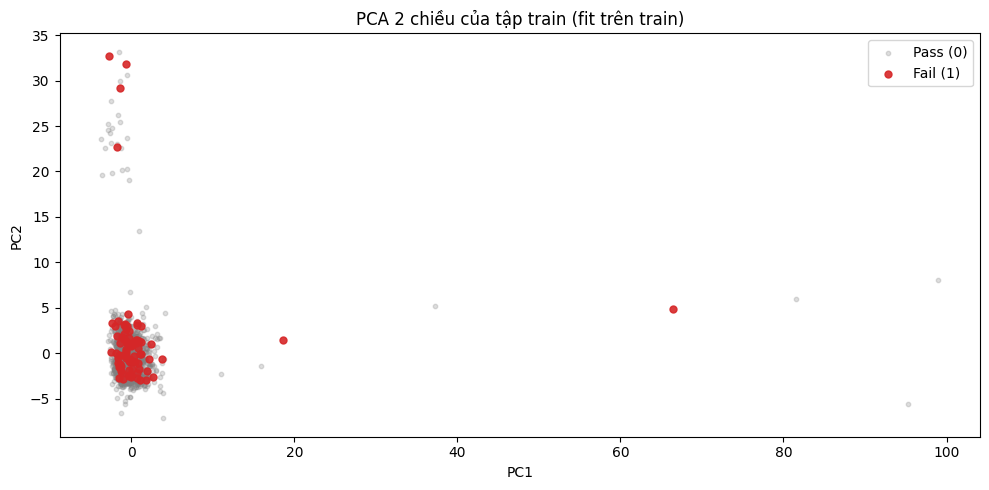

In [39]:
if RUN_OPTIONAL:
    is_fail = (y_train == 1).values

    plt.figure(figsize=(10, 5))
    # Pass vẽ mờ, Fail vẽ màu nổi
    plt.scatter(X_train_pca[~is_fail, 0], X_train_pca[~is_fail, 1],
                s=10, alpha=0.25, color="tab:gray", label="Pass (0)")
    plt.scatter(X_train_pca[is_fail, 0], X_train_pca[is_fail, 1],
                s=25, alpha=0.9, color="tab:red", label="Fail (1)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("PCA 2 chiều của tập train (fit trên train)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_01_pca_2d.png", dpi=150)
    plt.show()

### Nhận xét

- **Phát hiện:** PC1 và PC2 chỉ giải thích 5,72% và 3,62% phương sai (tổng 9,34%) → thông tin trải trên rất nhiều chiều, 2 chiều không đại diện được dữ liệu.
- Điểm Fail nằm lẫn trong đám Pass, không tách thành vùng riêng; một vài điểm nằm rất xa (PC1 hoặc PC2 lớn) tương ứng với các giá trị cực trị ở mục 7.
- **Kết luận:** bài toán khó, không thể tách Pass/Fail chỉ bằng vài hướng biến thiên lớn nhất. Hình chỉ để minh hoạ, không dùng để chọn mô hình hay chọn đặc trưng.

## 10. Phân tích 3B

Bảng Broken / Bad Quality / Background; mỗi dòng theo dạng "bằng chứng → ảnh hưởng → bước xử lý ở chương 4".

### 10.1. Broken

**Phát hiện:**

- 41.951 ô thiếu, chiếm 4,54% ma trận 1.567 × 590; 538/590 cột có ít nhất một ô thiếu (mục 5.1).
- 8 cột thiếu hơn 70%: 4 cột thiếu 91,19% và 4 cột thiếu 85,58% (mục 5.3).
- Missing có cấu trúc theo nhóm: 538 cột chỉ có 22 mức số ô thiếu (100 cột cùng thiếu 6 ô, 12 cột cùng thiếu 1.018 ô); mỗi mẫu thiếu 4–152 ô, không mẫu nào đầy đủ (mục 5.4, 5.5).
- Số ô thiếu trung bình mỗi mẫu thay đổi theo tuần (mục 8).

**Ảnh hưởng:**

- Mô hình trong scikit-learn không nhận `NaN`; không thể xoá dòng vì dòng nào cũng thiếu.
- Cột thiếu trên 85% sau khi impute chủ yếu là giá trị điền, ít thông tin thật.
- Impute bằng thống kê của cả train lẫn test sẽ gây rò rỉ dữ liệu.

**Kết luận:** SECOM có vấn đề **Broken** rõ ràng → loại cột thiếu > 70% và impute trung vị, cả hai học trên train.

### 10.2. Bad Quality

**Phát hiện:**

- 116 cột hằng và 6 cột gần hằng (mục 6).
- 110/464 cột có hơn 5% giá trị ngoài biên IQR; 269/474 cột có |skew| > 2; vài cột có hai cụm giá trị hoặc một giá trị cực lớn (mục 7).
- Độ lệch chuẩn giữa các cột chênh khoảng 6,3 × 10⁷ lần (mục 7.4).
- 329 cặp cột có |r| > 0,95, trong đó 158 cặp có |r| > 0,99 (mục 9.1).
- 590 cột (466 sau khi lọc) trong khi train chỉ có 83 Fail; Fail chỉ chiếm 6,64% (mục 3, 4, 6).

**Ảnh hưởng:**

- Nhiều cột không có hoặc lặp lại thông tin, làm tăng số chiều.
- Giá trị cực trị và thang đo chênh lệch làm lệch các mô hình nhạy thang đo.
- Số chiều lớn so với số Fail → dễ overfit, dễ học nhiễu; Accuracy cao giả tạo vì mất cân bằng.

**Kết luận:** dữ liệu có vấn đề **Bad Quality**, cần lọc cột, chuẩn hoá, chọn đặc trưng và xử lý mất cân bằng trước khi xây dựng mô hình.

### 10.3. Background

**Phát hiện:**

- Cột chỉ có chỉ số 0–589: không có tên cảm biến, đơn vị đo, công đoạn đo.
- Không có định nghĩa cụ thể của Fail và thời điểm gán nhãn so với thời điểm đo.
- Không có thông tin chi phí bỏ sót Fail, chi phí báo nhầm hay downtime.
- Timestamp là bối cảnh duy nhất; tỉ lệ Fail theo tuần dao động 1,06%–23,08% (mục 8).
- Metadata UCI ghi 591 features nhưng file thực tế có 590 cột (mục 2).

**Ảnh hưởng:**

- Không diễn giải được ý nghĩa vật lý của một dự đoán hay của đặc trưng quan trọng.
- Không chọn được ngưỡng theo chi phí; không chắc mọi phép đo có sẵn tại thời điểm cần dự đoán.
- Random split có thể cho kết quả lạc quan hơn khi dữ liệu thay đổi theo thời gian.

**Kết luận:** SECOM có vấn đề **Background** → không gán ý nghĩa vật lý, không giả định chi phí, ghi rõ các hạn chế này.

### 10.4. Bảng tổng hợp 3B

Bằng chứng trong bảng lấy trực tiếp từ các biến đã tính ở mục 2–9. Bảng được lưu vào `artifacts/eda_3B.csv`.

In [40]:
# Broken
eda_3B_rows = []
eda_3B_rows.append({
    "Nhóm": "Broken", "Vấn đề": "Giá trị thiếu rải rác",
    "Bằng chứng": f"{total_missing} ô thiếu ({missing_percent:.2f}%), {len(columns_with_missing)}/{X.shape[1]} cột có missing",
    "Ảnh hưởng": "Mô hình không nhận NaN; impute sai gây lệch hoặc rò rỉ",
    "Xử lý ở chương 4": "Impute trung vị, fit trên train"
})
eda_3B_rows.append({
    "Nhóm": "Broken", "Vấn đề": "Cột thiếu rất nhiều",
    "Bằng chứng": f"{len(high_missing_features)} cột thiếu > 70% (cao nhất {missing_rate.max() * 100:.2f}%)",
    "Ảnh hưởng": "Cột chủ yếu là giá trị điền, ít thông tin thật",
    "Xử lý ở chương 4": "Loại cột thiếu > 70%, học trên train"
})
eda_3B_rows.append({
    "Nhóm": "Broken", "Vấn đề": "Thiếu theo nhóm cột và theo dòng",
    "Bằng chứng": f"{len(same_missing_groups)} mức số ô thiếu cho {len(columns_with_missing)} cột; mỗi mẫu thiếu {missing_per_row.min()}-{missing_per_row.max()} ô",
    "Ảnh hưởng": "Không xoá được dòng; missingness có thể gắn với thời gian",
    "Xử lý ở chương 4": "Giữ mọi dòng; missing indicator chỉ thử như ablation"
})

In [41]:
# Bad Quality (phần 1)
eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Cột hằng và gần hằng",
    "Bằng chứng": f"{len(constant_features)} cột hằng, {len(near_constant_features)} cột gần hằng (> 99% cùng giá trị)",
    "Ảnh hưởng": "Không có hoặc rất ít thông tin phân biệt",
    "Xử lý ở chương 4": "Loại cột hằng (fit trên train); cột gần hằng để bước chọn đặc trưng xử lý"
})
eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Outlier và phân bố lệch",
    "Bằng chứng": f"{int((outlier_ratio > 0.05).sum())}/{len(iqr_columns)} cột > 5% outlier IQR; {int((skewness.abs() > 2).sum())}/{len(skewness)} cột |skew| > 2",
    "Ảnh hưởng": "Giá trị cực trị kéo lệch mean/std và mô hình tuyến tính",
    "Xử lý ở chương 4": "Không xoá outlier; thử RobustScaler hoặc clipping như ablation"
})
eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Thang đo chênh lệch",
    "Bằng chứng": f"std từ {feature_std.min():.1e} đến {feature_std.max():.1f} (max/min ≈ {feature_std.max() / feature_std.min():.1e})",
    "Ảnh hưởng": "Cột có thang lớn lấn át trong mô hình nhạy thang đo",
    "Xử lý ở chương 4": "StandardScaler, fit trên train"
})

In [42]:
# Bad Quality (phần 2)
if RUN_OPTIONAL:
    corr_evidence = f"{n_pairs_095} cặp |r| > 0.95, {n_pairs_099} cặp |r| > 0.99"
else:
    corr_evidence = "Chưa chạy mục 9 (RUN_OPTIONAL = False)"

eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Tương quan cao giữa các cột",
    "Bằng chứng": corr_evidence,
    "Ảnh hưởng": "Thông tin lặp, hệ số mô hình kém ổn định",
    "Xử lý ở chương 4": "Chọn đặc trưng bằng F-test, chọn k bằng CV trong train"
})
eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Nhiều chiều so với số Fail",
    "Bằng chứng": f"{X.shape[1]} cột ({X_after_eda.shape[1]} sau lọc) so với {int(y_train.sum())} Fail ở train",
    "Ảnh hưởng": "Dễ overfit, dễ học nhiễu",
    "Xử lý ở chương 4": "Chọn đặc trưng bằng F-test, chọn k bằng CV trong train"
})
eda_3B_rows.append({
    "Nhóm": "Bad Quality", "Vấn đề": "Mất cân bằng lớp",
    "Bằng chứng": f"Fail {int(y.sum())}/{len(y)} ({y.mean() * 100:.2f}%)",
    "Ảnh hưởng": "Accuracy cao giả tạo; Recall của Fail thấp",
    "Xử lý ở chương 4": "class_weight và chọn ngưỡng; SMOTE như ablation"
})

In [43]:
# Background
eda_3B_rows.append({
    "Nhóm": "Background", "Vấn đề": "Thiếu ngữ cảnh cảm biến",
    "Bằng chứng": f"Cột chỉ có chỉ số 0-{X.shape[1] - 1}; không có tên, đơn vị, công đoạn",
    "Ảnh hưởng": "Không diễn giải được ý nghĩa vật lý",
    "Xử lý ở chương 4": "Không gán ý nghĩa vật lý; chỉ báo cáo theo chỉ số cột"
})
eda_3B_rows.append({
    "Nhóm": "Background", "Vấn đề": "Thiếu định nghĩa Fail, thời điểm gán nhãn, chi phí",
    "Bằng chứng": "Chỉ có nhãn -1/1; không có chi phí bỏ sót, báo nhầm, downtime",
    "Ảnh hưởng": "Không chọn ngưỡng theo chi phí; chưa chắc phép đo có sẵn lúc dự đoán",
    "Xử lý ở chương 4": "Không giả định chi phí; chọn ngưỡng chỉ trên train"
})
eda_3B_rows.append({
    "Nhóm": "Background", "Vấn đề": "Timestamp là bối cảnh duy nhất",
    "Bằng chứng": f"Tỉ lệ Fail theo tuần {weekly_summary['fail_rate_%'].min():.2f}%-{weekly_summary['fail_rate_%'].max():.2f}%",
    "Ảnh hưởng": "Random split trộn thời điểm, kết quả test có thể lạc quan",
    "Xử lý ở chương 4": "Không dùng timestamp làm feature; ghi hạn chế ở chương 7"
})
eda_3B_rows.append({
    "Nhóm": "Background", "Vấn đề": "Metadata lệch với file",
    "Bằng chứng": f"UCI ghi 591 features, file thực tế {max(field_counts)} trường mỗi dòng",
    "Ảnh hưởng": "Dễ đọc sai nếu chỉ tin metadata",
    "Xử lý ở chương 4": "Dùng đúng 590 cột của file"
})

In [44]:
eda_3B = pd.DataFrame(eda_3B_rows)

with pd.option_context("display.max_colwidth", None):
    display(eda_3B)

eda_3B.to_csv(ARTIFACT_DIR / "eda_3B.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", ARTIFACT_DIR / "eda_3B.csv")

,Nhóm,Vấn đề,Bằng chứng,Ảnh hưởng,Xử lý ở chương 4
0,Broken,Giá trị thiếu rải rác,"41951 ô thiếu (4.54%), 538/590 cột có missing",Mô hình không nhận NaN; impute sai gây lệch hoặc rò rỉ,"Impute trung vị, fit trên train"
1,Broken,Cột thiếu rất nhiều,8 cột thiếu > 70% (cao nhất 91.19%),"Cột chủ yếu là giá trị điền, ít thông tin thật","Loại cột thiếu > 70%, học trên train"
2,Broken,Thiếu theo nhóm cột và theo dòng,22 mức số ô thiếu cho 538 cột; mỗi mẫu thiếu 4-152 ô,Không xoá được dòng; missingness có thể gắn với thời gian,Giữ mọi dòng; missing indicator chỉ thử như ablation
3,Bad Quality,Cột hằng và gần hằng,"116 cột hằng, 6 cột gần hằng (> 99% cùng giá trị)",Không có hoặc rất ít thông tin phân biệt,Loại cột hằng (fit trên train); cột gần hằng để bước chọn đặc trưng xử lý
4,Bad Quality,Outlier và phân bố lệch,110/464 cột > 5% outlier IQR; 269/474 cột |skew| > 2,Giá trị cực trị kéo lệch mean/std và mô hình tuyến tính,Không xoá outlier; thử RobustScaler hoặc clipping như ablation
5,Bad Quality,Thang đo chênh lệch,std từ 1.0e-04 đến 6553.6 (max/min ≈ 6.3e+07),Cột có thang lớn lấn át trong mô hình nhạy thang đo,"StandardScaler, fit trên train"
6,Bad Quality,Tương quan cao giữa các cột,"329 cặp |r| > 0.95, 158 cặp |r| > 0.99","Thông tin lặp, hệ số mô hình kém ổn định","Chọn đặc trưng bằng F-test, chọn k bằng CV trong train"
7,Bad Quality,Nhiều chiều so với số Fail,590 cột (466 sau lọc) so với 83 Fail ở train,"Dễ overfit, dễ học nhiễu","Chọn đặc trưng bằng F-test, chọn k bằng CV trong train"
8,Bad Quality,Mất cân bằng lớp,Fail 104/1567 (6.64%),Accuracy cao giả tạo; Recall của Fail thấp,class_weight và chọn ngưỡng; SMOTE như ablation
9,Background,Thiếu ngữ cảnh cảm biến,"Cột chỉ có chỉ số 0-589; không có tên, đơn vị, công đoạn",Không diễn giải được ý nghĩa vật lý,Không gán ý nghĩa vật lý; chỉ báo cáo theo chỉ số cột


Đã lưu: artifacts\eda_3B.csv


### Kết luận 3B

SECOM không chỉ có vấn đề **thiếu dữ liệu** (Broken) mà còn có nhiều cột ít thông tin, lệch, lặp lại và mất cân bằng lớp (Bad Quality), đồng thời thiếu ngữ cảnh nghiệp vụ (Background). Mỗi vấn đề trong bảng đều có một bước xử lý tương ứng ở chương 4; riêng các hạn chế Background không xử lý được bằng code mà phải ghi rõ trong báo cáo.

## 11. Hình thành bài toán AI và đánh giá mức sẵn sàng của dữ liệu

Xác định loại bài toán (classification), nhãn, đặc trưng, thước đo; đánh giá dữ liệu đã đủ sẵn sàng chưa.

### 11.1. Ba bài toán AI có thể hình thành

| Bài toán | Input | Output | Loại AI | Người dùng | Quyết định |
|---|---|---|---|---|---|
| 1. Dự đoán Pass/Fail | 590 phép đo quá trình của một quan sát | Pass/Fail hoặc điểm rủi ro Fail | **Classification** | Kỹ sư chất lượng, kỹ sư quy trình | Quan sát nào cần kiểm tra thêm hoặc điều tra |
| 2. Quality monitoring / phát hiện bất thường | Các tín hiệu quá trình theo thời gian | Cảnh báo, mức rủi ro chất lượng | Anomaly detection / monitoring | Kỹ sư quy trình | Kiểm tra sâu một công đoạn hoặc nhóm tín hiệu |
| 3. Feature / sensor selection | 590 tín hiệu và nhãn Pass/Fail | Danh sách tín hiệu liên quan nhất đến Fail | Feature selection / phân tích giải thích | Kỹ sư quy trình | Tập trung theo dõi các tín hiệu quan trọng |

**Bài toán chính của đồ án: Classification Pass/Fail**, vì:

1. Dataset có sẵn nhãn Pass/Fail cho mọi quan sát.
2. Đầu ra phục vụ trực tiếp quyết định "quan sát nào cần kiểm tra thêm".
3. Đánh giá được bằng các chỉ số rõ ràng trên tập test (Recall, Precision, F1 của Fail, PR-AUC).

Bài toán 2 cần định nghĩa "bình thường / bất thường" và ngữ cảnh vận hành mà dataset không có. Bài toán 3 được làm như một bước bên trong bài toán 1 (chọn đặc trưng), không làm riêng.

- **Nhãn:** `y` (0 = Pass, 1 = Fail). **Đặc trưng:** 590 phép đo (trước khi lọc), không gồm timestamp.
- **Thước đo:** Recall, Precision, F1 của lớp Fail, PR-AUC; không dùng Accuracy làm thước đo chính.

### 11.2. Mức sẵn sàng của dữ liệu

**Điểm thuận lợi:**

1. 1.567 quan sát, 590 phép đo, đủ cho một nghiên cứu ban đầu.
2. Mọi quan sát đều có nhãn Pass/Fail và timestamp hợp lệ.
3. Không có dòng trùng; file đọc đúng cấu trúc.
4. Dữ liệu từ một quy trình sản xuất bán dẫn thực tế.

**Hạn chế:**

1. 4,54% ô thiếu, 8 cột thiếu hơn 70%, không mẫu nào đầy đủ.
2. 116 cột hằng, nhiều cột lệch mạnh, có giá trị cực trị, thang đo chênh gần 8 bậc.
3. Nhiều cặp cột tương quan gần tuyệt đối.
4. Chỉ 104 Fail (83 ở train, 21 ở test).
5. Không có ngữ cảnh cảm biến, định nghĩa Fail, chi phí.
6. Tỉ lệ Fail và missing thay đổi theo thời gian.

**Việc cần làm trước khi xây dựng mô hình:**

1. Chia train/test stratified trước (đã làm), mọi phép fit chỉ học trên train.
2. Loại cột thiếu > 70% và cột hằng, impute trung vị.
3. Chuẩn hoá đặc trưng.
4. Chọn đặc trưng bằng F-test, chọn k bằng cross-validation trong train.
5. Thiết kế cách đánh giá phù hợp với mất cân bằng và chọn ngưỡng chỉ trên train.
6. Ghi lại hạn chế về thời gian và về ngữ cảnh.

**Đánh giá:** dữ liệu **chưa sẵn sàng** để huấn luyện ngay, nhưng đủ để làm một nghiên cứu ban đầu sau khi tiền xử lý.

### 11.3. Câu hỏi: cần bổ sung thông tin gì trước khi triển khai ở nhà máy thật?

- Tên, đơn vị, công đoạn của từng phép đo, và phép đo đó có sẵn tại thời điểm nào so với thời điểm cần dự đoán.
- Định nghĩa Fail và thời điểm gán nhãn.
- Chi phí bỏ sót một Fail và chi phí kiểm tra thêm một quan sát, cùng năng lực kiểm tra mỗi ngày, để chọn ngưỡng.
- Quy trình xử lý sau khi có cảnh báo (ai nhận, làm gì).
- Dữ liệu dài hơn theo thời gian để kiểm tra sự thay đổi phân bố và đánh giá kiểu "train trên quá khứ, test trên tương lai".

## 12. Kết luận và danh sách quyết định tiền xử lý rút ra từ EDA

Liệt kê các quyết định (lọc cột, impute, outlier, scale, imbalance) kèm bằng chứng để notebook 02 dùng lại.

### Quyết định tiền xử lý dự kiến cho notebook 02

| Vấn đề | Bằng chứng (mục) | Quyết định | Kiểm chứng ở notebook 03 |
|---|---|---|---|
| Cột thiếu rất nhiều | 8 cột thiếu > 70%; ngưỡng 70% và 80% cho cùng kết quả, không có cột nào thiếu trong khoảng 65–85% (mục 5.3) | Loại cột thiếu > 70%, ngưỡng áp dụng khi học trên train | Kiểm tra số cột bị loại khi fit trên train; bước lọc nằm trong pipeline khi chạy CV |
| Giá trị thiếu rải rác | 41.951 ô thiếu (4,54%), mọi mẫu đều thiếu 4–152 ô (mục 5.1, 5.5) | Impute trung vị, fit trên train | Imputer nằm trong pipeline, fit lại trong từng fold CV |
| Cột hằng | 116 cột phương sai bằng 0; 590 → 582 → 466 (mục 6) | Loại cột hằng (`VarianceThreshold`), fit trên train | Số cột còn lại sau pipeline trên train |
| Outlier, phân bố lệch | 110/464 cột > 5% outlier IQR; 269/474 cột \|skew\| > 2 (mục 7) | Không xoá outlier | Ablation: `StandardScaler` so với `RobustScaler` hoặc clipping |
| Thang đo chênh lệch | std chênh khoảng 6,3 × 10⁷ lần (mục 7.4) | `StandardScaler`, fit trên train | Bước scaler trong pipeline; so sánh trong ablation ở trên |
| Mất cân bằng lớp | Fail 6,64%; train 83 Fail, test 21 Fail (mục 3, 4) | `class_weight` và chọn ngưỡng trên dự đoán out-of-fold của train | Ablation: SMOTE (chỉ trong fold train) so với `class_weight` |
| Nhiều chiều, tương quan cao | 466 cột sau lọc so với 83 Fail; 329 cặp \|r\| > 0,95 (mục 6, 9.1) | Chọn đặc trưng bằng F-test, chọn k bằng cross-validation trong train | So sánh các giá trị k bằng CV trên train |
| Missing theo nhóm và theo thời gian | 22 mức số ô thiếu cho 538 cột; missing trung bình mỗi mẫu thay đổi theo tuần (mục 5.4, 8) | Không thêm missing indicator vào pipeline chính | Ablation: có / không có missing indicator |
| Timestamp | Tỉ lệ Fail theo tuần 1,06%–23,08% (mục 8) | Timestamp **không** làm feature | Kiểm tra danh sách cột đầu vào không có timestamp; ghi hạn chế random split ở chương 7 |

## Kết luận

Notebook này phát biểu bài toán và khảo sát dữ liệu SECOM. File thực tế có 1.567 quan sát × 590 cột (UCI ghi 591), nhãn và timestamp đầy đủ, không có dòng trùng. Phân tích 3B: **Broken** – 41.951 ô thiếu (4,54%), 8 cột thiếu hơn 70%, mẫu nào cũng thiếu ít nhất 4 ô; **Bad Quality** – 116 cột hằng, nhiều cột lệch mạnh, thang đo chênh gần 8 bậc, 329 cặp cột có |r| > 0,95; **Background** – không có tên cảm biến, định nghĩa Fail hay chi phí, timestamp là bối cảnh duy nhất. Fail chỉ chiếm 6,64% (83 Fail ở train, 21 ở test) nên không dùng Accuracy làm thước đo chính. Tỉ lệ Fail theo tuần dao động 1,06%–23,08%, nên random split có thể cho kết quả lạc quan, cần ghi ở chương 7. Bài toán được chọn là phân loại Pass/Fail; dữ liệu chưa sẵn sàng để huấn luyện ngay. Notebook 02 sẽ đọc dữ liệu bằng `load_secom`, chia bằng `get_split` và xây pipeline tiền xử lý fit trên train theo bảng quyết định ở mục 12; bảng 3B ở `artifacts/eda_3B.csv` dùng để tham chiếu.

## Điểm cần ghi nhớ

- Kiểm tra file thực tế trước khi tin metadata: SECOM có 590 cột, không tự thêm cột thứ 591.
- Thống kê mô tả không dùng nhãn chạy trên toàn bộ `X`; mọi phép fit và phân tích đặc trưng – nhãn chỉ chạy trên train.
- Chia train/test stratified **trước** khi học bất kỳ tham số nào.
- Fail chỉ 6,64%: luôn dự đoán Pass vẫn đạt Accuracy 93,36% nhưng Recall của Fail = 0.
- Ngưỡng 70% là quy ước; với SECOM, kết quả không đổi nếu ngưỡng nằm trong khoảng 65–85%.
- Outlier theo IQR chỉ là công cụ sàng lọc, không xoá một cách máy móc.
- Timestamp không làm feature; sự thay đổi theo thời gian là một hạn chế cần báo cáo.
- Không gán ý nghĩa vật lý cho cột khi dataset không cung cấp.